# Ablación de la arquitectura de la red funcional
Ablaciones de la arquitectura de la red funcional fuera de los rangos del enunciado. Las funciones están en `funciones/Ablacion_arquitectura.py` y usan `funciones/Entrenamiento_red.py`.

| Sección | Qué cambia | Qué se mantiene |
|---|---|---|
| 1 | q (neuronas funcionales) y M (componentes FPCA) | Cabezas lineal, MLP y KAN; ONI como promedio anual |
| 2 | Capas ocultas, ancho e intervalos de la KAN | Mejor q y M de la KAN |
| 3 | Forma del ONI: promedio anual, máximo, ventana DEF y curva | Mejor configuración de cada cabeza |
| 4 | — | Evaluación y diagnóstico del mejor modelo de cada cabeza |

Escala del modelo: √P aplicada a la curva suavizada en mm. Evaluación en validación: estaciones de validación en 1996–2000, que no están en entrenamiento. Las estaciones de prueba (2001–2003) no se usan. Tres semillas por configuración, λ = 100, lote completo, AdamW con tasa 0,01 y parada temprana con paciencia de 200 épocas. Los resultados de cada sección se guardan en `Resultados_Ablacion_arquitectura/` y se cargan si ya existen.

## Configuración y datos

In [1]:
import sys
sys.path.append('funciones')
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
import Ablacion_arquitectura as Ab

torch.set_num_threads(6)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
D = Ab.preparar_datos()
print('Curvas: entrenamiento', D['tr'].sum(), '| validación', D['va'].sum())

Curvas: entrenamiento 1300 | validación 102


### Métricas
Todas las métricas se calculan frente a la curva suavizada de la estación (en mm, recortada en 0 como las predicciones).
- **RECM_mm**: raíz del error cuadrático medio en las 72 péntadas.
- **sesgo_%**: diferencia porcentual entre el acumulado anual predicho y el de la curva de la estación.
- **L2_relativo**: $\|\hat y - y\| / \|y\|$ en la malla fina, promedio de las curvas.
- **KGE**: $1 - \sqrt{(r-1)^2 + (\alpha-1)^2 + (\beta-1)^2}$, mediana de las curvas.
- **pico1_pentadas / pico2_pentadas**: error en la fecha del máximo de marzo–junio y de septiembre–diciembre.

### Referencias: curva satelital sin corregir, climatología y regresiones funcionales

In [2]:
tabla_referencias = Ab.referencias(D)
SATELITE = tabla_referencias.loc['Satélite sin corregir', 'RECM_mm']
tabla_referencias.round(3)

,RECM_mm,sesgo_%,L2_relativo,KGE,pico1_pentadas,pico2_pentadas
Satélite sin corregir,15.639,5.410,0.538,0.326,4.143,6.480
Climatología de entrenamiento,18.008,-0.279,0.518,0.349,4.349,2.257
Regresión: Funcion a funcion,15.875,-20.130,NaN,NaN,NaN,NaN
Regresión: Concurrente con covariables,15.567,-2.819,NaN,NaN,NaN,NaN


### Formas del ONI
Promedio anual, máximo del año (con signo), ventana DEF y curva de las 12 ventanas en [0, 72] (base B-spline con K = 6), que entra a la red con sus propias neuronas funcionales.

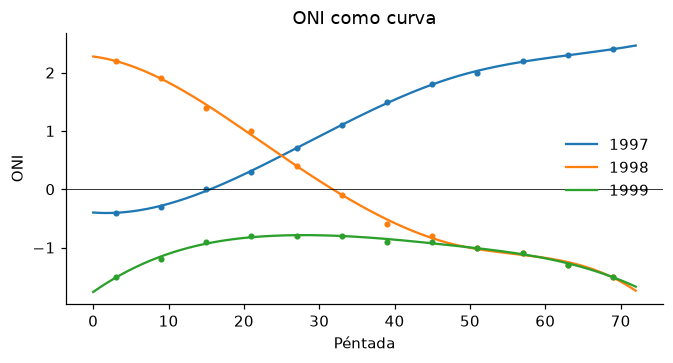

In [3]:
Ab.grafica_oni_curva(D); plt.show()

## 1. q y M
q ∈ {2, 4, 8, 12, 16} y M ∈ {2, …, 6} para las tres cabezas (M ≤ 6 porque la base de estaciones tiene K = 6).

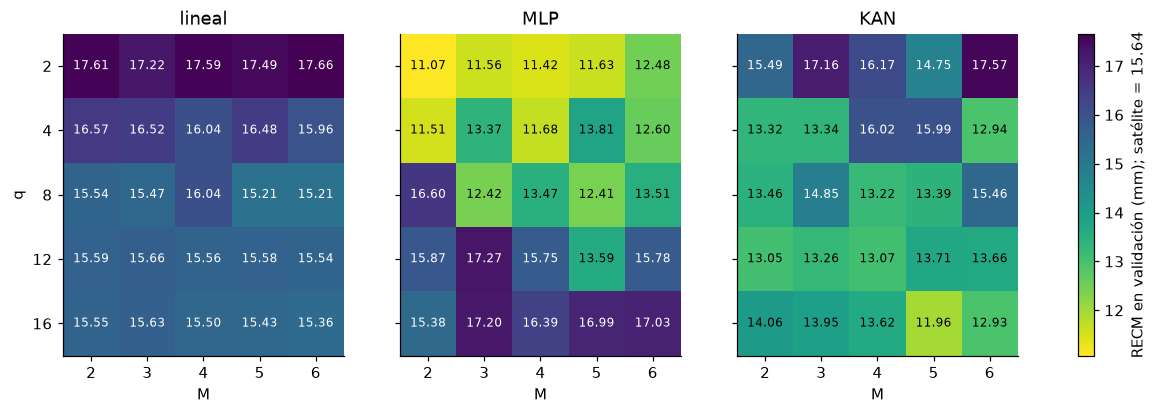

In [4]:
def etapa_1(registros):
    for cabeza in Ab.CABEZAS:
        for q in (2, 4, 8, 12, 16):
            for m in (2, 3, 4, 5, 6):
                Ab.correr(D, registros, cabeza, q, m)
e1 = Ab.etapa('etapa_1_q_M', etapa_1)
Ab.grafica_q_M(e1, SATELITE); plt.show()

In [5]:
Ab.resumen(e1, ['cabeza', 'M']).unstack('cabeza')['RECM_mm']

cabeza,KAN,MLP,lineal
M,,,
2,13.87,14.09,16.17
3,14.51,14.36,16.10
4,14.42,13.74,16.14
5,13.96,13.69,16.04
6,14.51,14.28,15.95


In [6]:
Ab.resumen(e1, ['cabeza', 'q']).unstack('cabeza')['RECM_mm']

cabeza,KAN,MLP,lineal
q,,,
2,16.23,11.63,17.51
4,14.32,12.59,16.32
8,14.08,13.68,15.49
12,13.35,15.65,15.59
16,13.30,16.60,15.49


In [7]:
mejores_1 = Ab.resumen(e1, ['cabeza', 'q', 'M']).reset_index().sort_values('L2_validacion').groupby('cabeza').head(1)
mejores_1

,cabeza,q,M,RECM_mm,sesgo_%,L2_validacion,RECM_sd
25,MLP,2,2,11.07,-5.49,87.54,0.16
23,KAN,16,5,11.96,-2.32,99.78,0.53
63,lineal,8,5,15.21,-9.57,122.92,0.18


## 2. Arquitectura de la KAN
Capas ocultas [2], [4], [8], [16], [2, 2], [4, 4] y [8, 8], con 6, 12 o 20 intervalos en las B-splines de cada arista.

In [8]:
fila = mejores_1.set_index('cabeza').loc['KAN']; q_k, m_k = int(fila.q), int(fila.M)
def etapa_2(registros):
    for anchos in ((2,), (4,), (8,), (16,), (2, 2), (4, 4), (8, 8)):
        for intervalos in (6, 12, 20):
            Ab.correr(D, registros, 'KAN', q_k, m_k, anchos=anchos, intervalos=intervalos)
e2 = Ab.etapa('etapa_2_KAN', etapa_2)
r2 = Ab.resumen(e2, ['anchos', 'intervalos'], ('RECM_mm', 'sesgo_%', 'L2_validacion', 'parametros_cabeza', 'epoca'))
r2.sort_values('L2_validacion')

RECM_mm  sesgo_%  L2_validacion  parametros_cabeza   epoca  \
anchos intervalos                                                               
(16,)  20            11.76    -1.10          92.60             9200.0   17.33   
       12            11.89    -1.42          94.37             6256.0   17.33   
(4,)   12            11.89    -0.49          95.26             1564.0   32.00   
(8, 8) 20            12.01    -3.73          95.74             6200.0   24.00   
(8,)   6             11.45    -1.34          96.11             2024.0   30.67   
(8, 8) 12            12.01     0.96          96.98             4216.0   31.33   
(8,)   20            12.29    -0.89          97.17             4600.0   24.33   
(16,)  6             11.82    -5.82          97.52             4048.0   13.00   
(4, 4) 20            12.15    -2.62          99.40             2700.0   51.00   
(2,)   12            11.96    -2.32          99.78              782.0  133.33   
(4,)   20            12.20    -2.85         100.26             2300.0   42.67   
(4, 4) 12            12.17    -2.77         100.77             1836.0   52.33   
(8, 8) 6             12.34    -4.50         100.98             2728.0   34.33   
(8,)   12            12.18     1.76         101.13             3128.0   28.67   
(2, 2) 20            12.52    -3.58         102.92             1250.0  240.67   
(2,)   20            12.14    -8.00         103.04             1150.0  144.33   
       6             12.32    -0.48         103.30              506.0   53.00   
(4,)   6             12.23    -3.33         104.81             1012.0   94.00   
(2, 2) 12            12.58    -4.46         105.82              850.0  126.33   
(4, 4) 6             12.99     0.77         109.72             1188.0   49.67   
(2, 2) 6             13.95    -3.79         113.70              550.0   92.67   

                   RECM_sd  
anchos intervalos           
(16,)  20             1.28  
       12             0.88  
(4,)   12             0.16  
(8, 8) 20             0.75  
(8,)   6              0.49  
(8, 8) 12             0.49  
(8,)   20             0.82  
(16,)  6              0.63  
(4, 4) 20             0.66  
(2,)   12             0.53  
(4,)   20             0.46  
(4, 4) 12             1.33  
(8, 8) 6              1.22  
(8,)   12             0.09  
(2, 2) 20             2.41  
(2,)   20             1.01  
       6              1.05  
(4,)   6              1.19  
(2, 2) 12             1.33  
(4, 4) 6              1.33  
(2, 2) 6              2.26

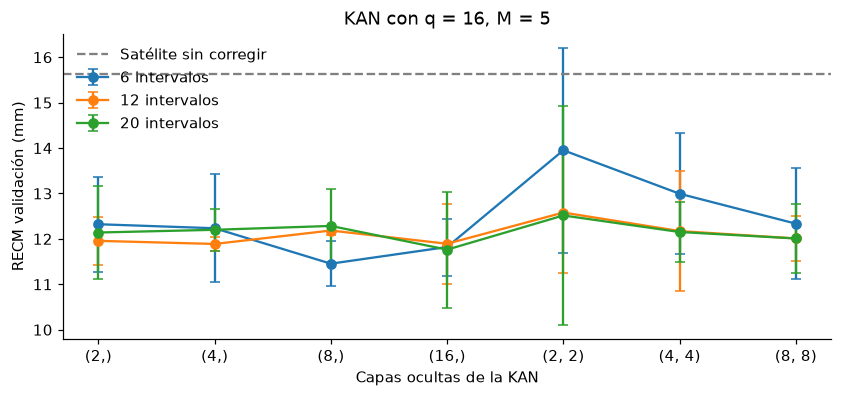

In [9]:
Ab.grafica_arquitectura_kan(e2, SATELITE, f'KAN con q = {q_k}, M = {m_k}'); plt.show()

### Elección de la arquitectura de la KAN
Se comparan tres KAN de una capa oculta: la de menor pérdida de validación ([16] con 20 intervalos), una de 4 nodos con 12 intervalos y la más pequeña ([2] con 6 intervalos). Además de las métricas y su desviación entre semillas, se reporta el cambio relativo de los coeficientes del codificador respecto a su inicialización y la fracción de entradas de entrenamiento fuera del soporte de las B-splines.

Criterio: entre las arquitecturas con RECM dentro de la desviación entre semillas de la de menor pérdida, se elige la de menor desviación entre semillas. Se usa la KAN de una capa con 4 nodos y 12 intervalos.

In [10]:
candidatos = [((16,), 20), ((4,), 12), ((2,), 6)]
e2b = Ab.etapa('etapa_2_eleccion_KAN', lambda registros: Ab.diagnostico_arquitecturas(D, registros, candidatos, q_k, m_k))
eleccion = e2b.groupby(['anchos', 'intervalos'], sort=False).agg(
    parametros_cabeza=('parametros_cabeza', 'first'), epoca=('epoca', 'mean'), L2_validacion=('L2_validacion', 'mean'),
    RECM_mm=('RECM_mm', 'mean'), RECM_sd=('RECM_mm', 'std'), sesgo=('sesgo_%', 'mean'),
    cambio_codificador=('cambio_codificador', 'mean'), fuera_soporte=('fuera_soporte', 'mean'))
eleccion.round(3)

,,parametros_cabeza,epoca,L2_validacion,RECM_mm,RECM_sd,sesgo,cambio_codificador,fuera_soporte
anchos,intervalos,,,,,,,,
"(16,)",20,9200,17.333,92.603,11.764,1.277,-1.103,0.107,0.127
"(4,)",12,1564,32.000,95.265,11.889,0.164,-0.491,0.217,0.072
"(2,)",6,506,53.000,103.303,12.323,1.047,-0.475,0.362,0.130


In [11]:
anchos_k, intervalos_k = '(4,)', 12
config = {c: dict(q=int(r.q), M=int(r.M)) for c, r in mejores_1.set_index('cabeza').iterrows()}
config['KAN'].update(anchos=Ab.texto_anchos(anchos_k), intervalos=int(intervalos_k))
config

{'MLP': {'q': 2, 'M': 2},
 'KAN': {'q': 16, 'M': 5, 'anchos': (4,), 'intervalos': 12},
 'lineal': {'q': 8, 'M': 5}}

## 3. Forma del ONI
Promedio anual, máximo del año, ventana DEF y curva, con la mejor configuración de cada cabeza.

In [12]:
def etapa_3(registros):
    for oni in ('promedio anual', 'máximo', 'DEF', 'curva'):
        for cabeza, cfg in config.items():
            cfg = dict(cfg); q, m = cfg.pop('q'), cfg.pop('M')
            Ab.correr(D, registros, cabeza, q, m, oni=oni, **cfg)
e3 = Ab.etapa('etapa_3_ONI', etapa_3)
Ab.resumen(e3, ['cabeza', 'oni']).unstack('oni')

RECM_mm                              sesgo_%               \
oni        DEF  curva máximo promedio anual     DEF curva máximo   
cabeza                                                             
KAN      11.69  12.16  11.92          11.89   -7.15 -5.35  -6.10   
MLP      12.00  16.11  11.29          11.07   -8.27 -6.68  -9.17   
lineal   16.24  16.44  15.54          15.21  -10.46 -9.52 -11.65   

                      L2_validacion                                RECM_sd  \
oni    promedio anual           DEF   curva  máximo promedio anual     DEF   
cabeza                                                                       
KAN             -0.49         96.38   97.70   97.37          95.26    0.53   
MLP             -5.49         97.69  144.27   88.53          87.54    0.32   
lineal          -9.57        144.40  142.79  130.75         122.92    0.89   

                                    
oni    curva máximo promedio anual  
cabeza                              
KAN     0.44   0.20           0.16  
MLP     3.17   0.22           0.16  
lineal  0.95   0.44           0.18

ONI con menor pérdida de validación: promedio anual


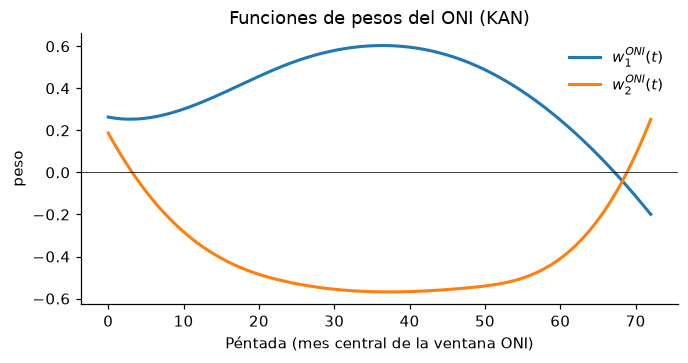

In [13]:
mejor_oni = Ab.resumen(e3, ['oni'])['L2_validacion'].idxmin()
print('ONI con menor pérdida de validación:', mejor_oni)
cfg = dict(config['KAN']); q, m = cfg.pop('q'), cfg.pop('M')
red_oni, _ = Ab.red_guardada(D, 'KAN_oni_curva_semilla1', 'KAN', q, m, 1, oni='curva', **cfg)
Ab.grafica_pesos_oni(D, red_oni); plt.show()

## 4. Evaluación y diagnóstico del mejor modelo
Objetivo directo, mejor configuración de cada cabeza y ONI de la sección 3. Predicción promedio de las 3 semillas.

In [14]:
finales, predicciones = {}, {}
for cabeza in Ab.CABEZAS:
    finales[cabeza], predicciones[cabeza] = Ab.modelo_final(D, f'final_{cabeza}', cabeza, config[cabeza], mejor_oni)
tabla_final = pd.concat([tabla_referencias,
                         pd.DataFrame({f'Red {c}': Ab.metricas(D, *p) for c, p in predicciones.items()}).T])
tabla_final.round(3)

,RECM_mm,sesgo_%,L2_relativo,KGE,pico1_pentadas,pico2_pentadas
Satélite sin corregir,15.639,5.410,0.538,0.326,4.143,6.480
Climatología de entrenamiento,18.008,-0.279,0.518,0.349,4.349,2.257
Regresión: Funcion a funcion,15.875,-20.130,NaN,NaN,NaN,NaN
Regresión: Concurrente con covariables,15.567,-2.819,NaN,NaN,NaN,NaN
Red lineal,15.181,-9.567,0.428,0.445,3.982,2.293
Red MLP,10.862,-5.494,0.383,0.508,4.099,2.246
Red KAN,11.259,-0.491,0.397,0.485,4.377,2.165


### Media en validación y sesgo por péntada

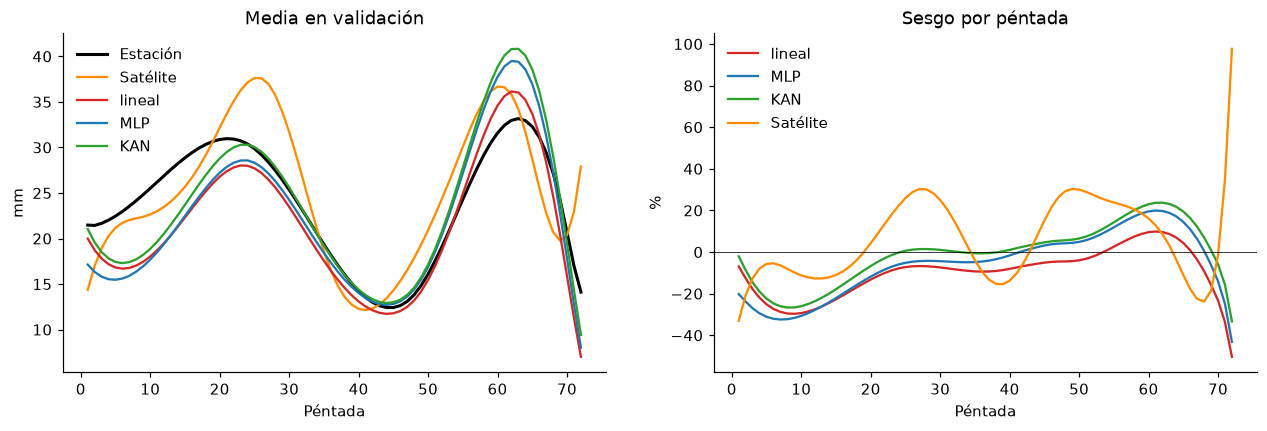

In [15]:
Ab.grafica_media_sesgo(D, predicciones); plt.show()

### Curvas de ejemplo: mejor, típica y peor de la KAN

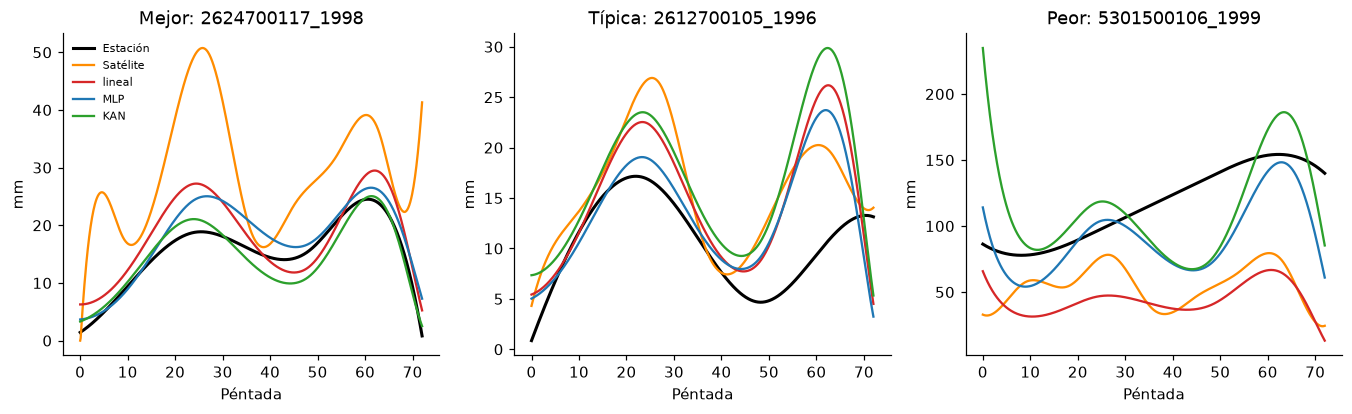

In [16]:
Ab.grafica_casos(D, predicciones); plt.show()

### Funciones de pesos $w_k(t)$ del satélite (KAN)
En gris, la curva media del satélite escalada.

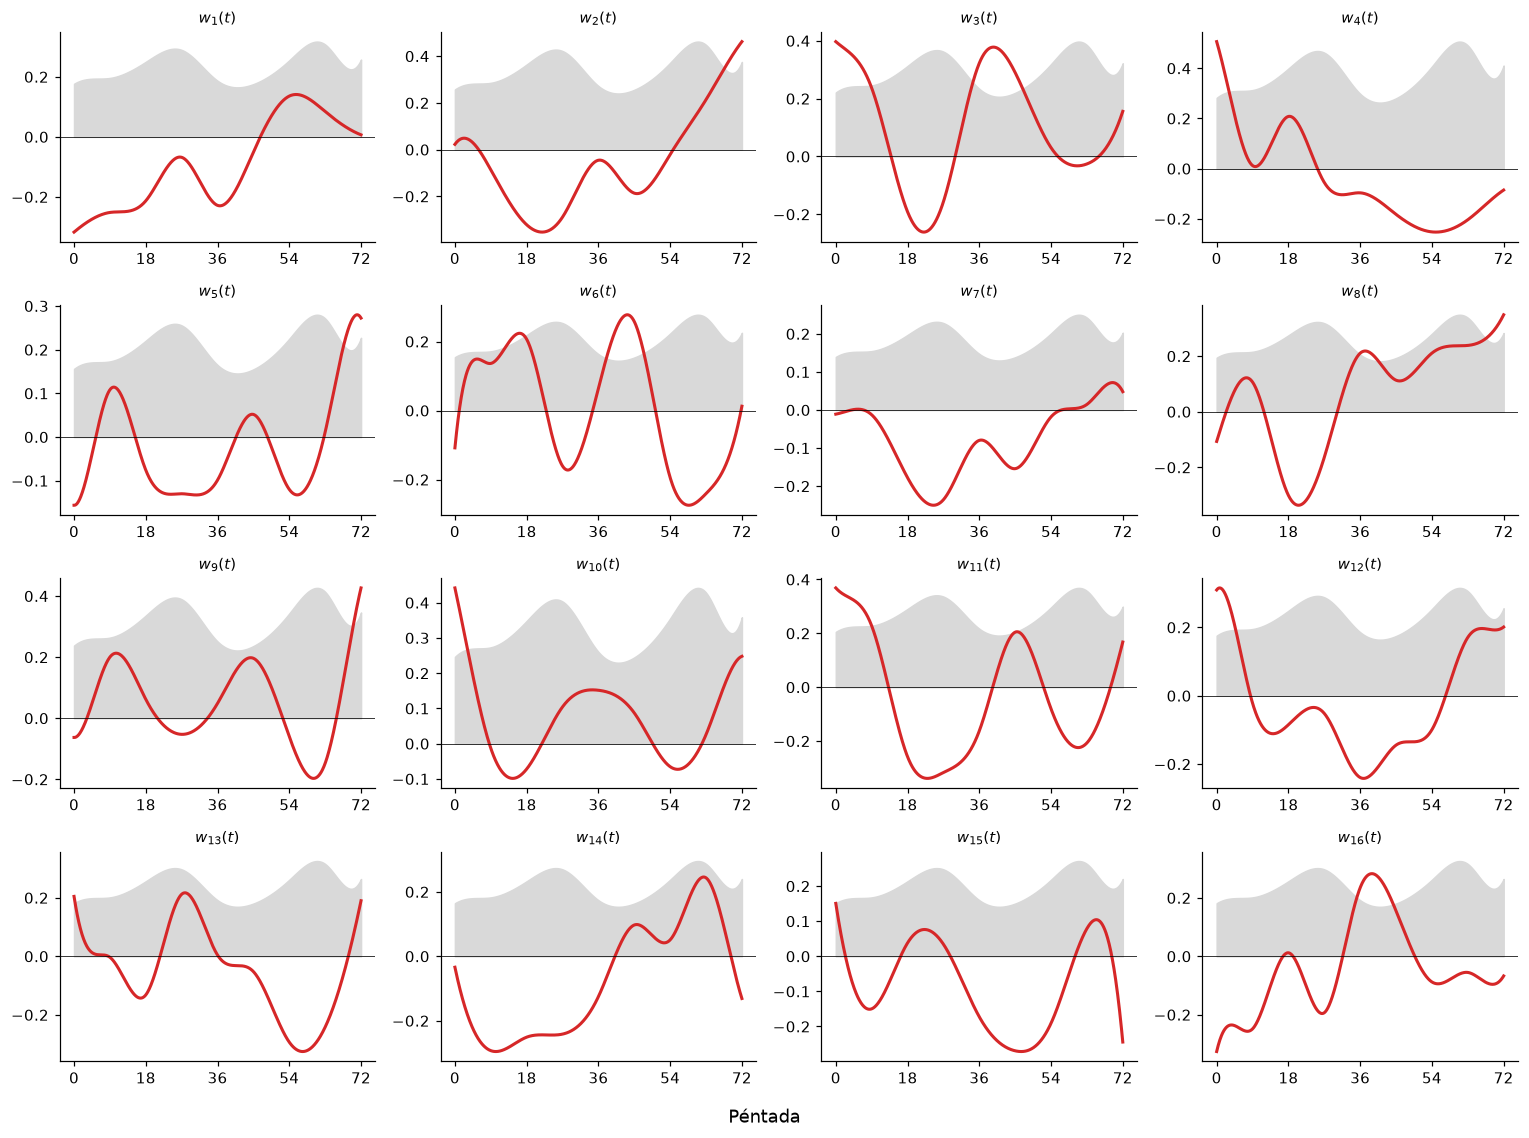

In [17]:
Ab.grafica_pesos_satelite(D, finales['KAN']); plt.show()

### Funciones propias de la FPCA

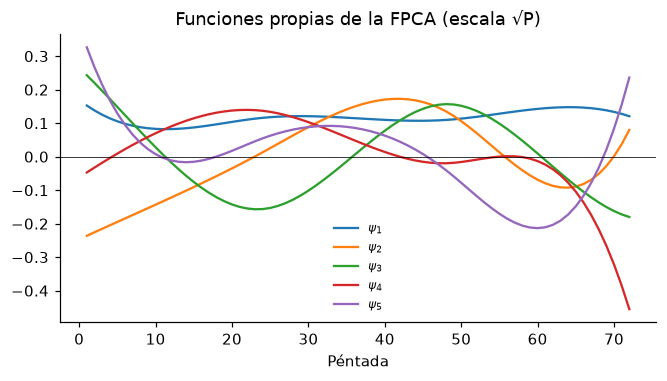

In [18]:
Ab.grafica_fpca(D, config['KAN']['M']); plt.show()

### Activaciones de la KAN
Cada panel es una arista $\varphi(x)$ en el rango de los datos de entrenamiento.

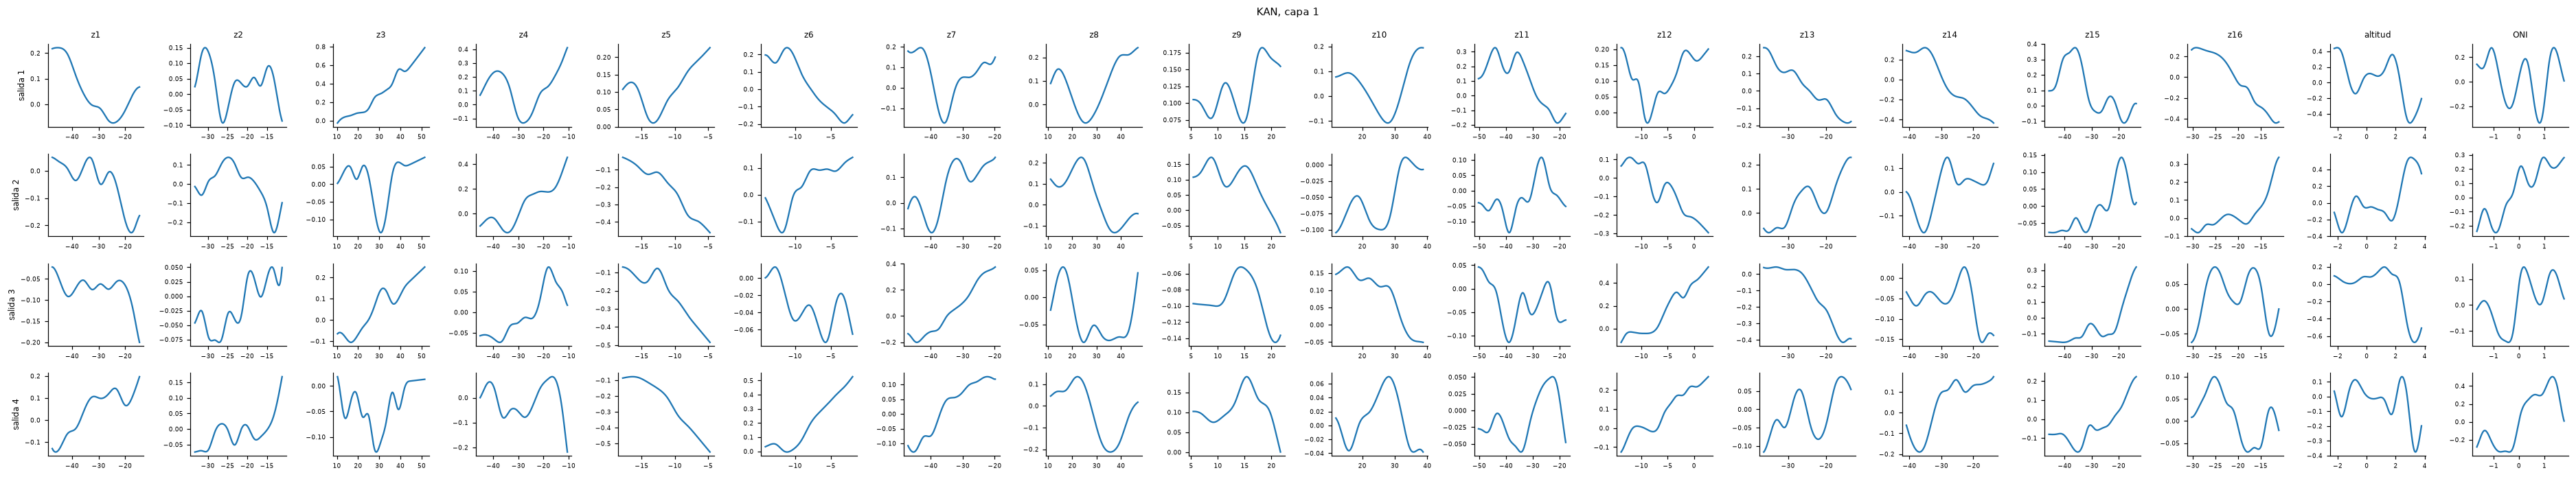

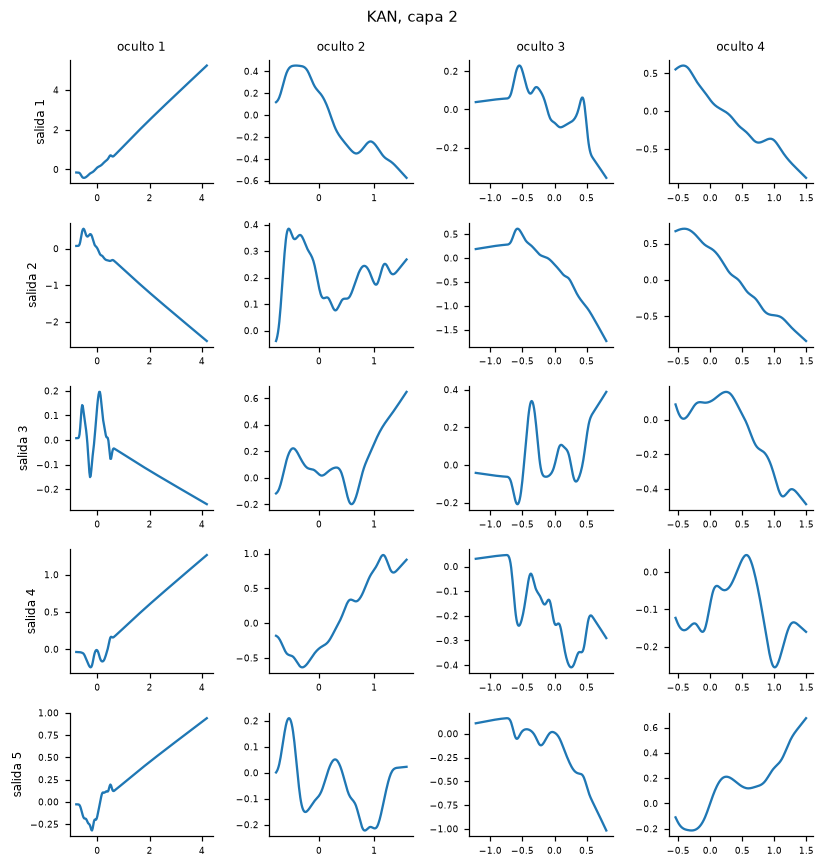

In [19]:
for fig in Ab.graficas_activaciones_kan(D, finales['KAN'], mejor_oni): plt.show()

### Amplitud de las aristas de la primera capa

In [20]:
Ab.amplitud_aristas(D, finales['KAN'], mejor_oni)

,z1,z2,z3,z4,z5,z6,z7,z8,z9,z10,z11,z12,z13,z14,z15,z16,altitud,ONI
oculto 1,0.29,0.24,0.81,0.54,0.22,0.43,0.37,0.32,0.11,0.30,0.51,0.24,0.44,0.75,0.49,0.72,0.95,0.61
oculto 2,0.28,0.39,0.21,0.61,0.43,0.28,0.29,0.35,0.25,0.12,0.25,0.41,0.31,0.32,0.22,0.42,0.88,0.52
oculto 3,0.18,0.13,0.35,0.18,0.42,0.09,0.57,0.14,0.08,0.22,0.16,0.66,0.46,0.19,0.47,0.15,0.86,0.28
oculto 4,0.33,0.24,0.15,0.30,0.48,0.53,0.25,0.35,0.19,0.11,0.11,0.40,0.21,0.36,0.39,0.17,0.51,0.84


### Puntajes FPCA predichos frente a reales (KAN)

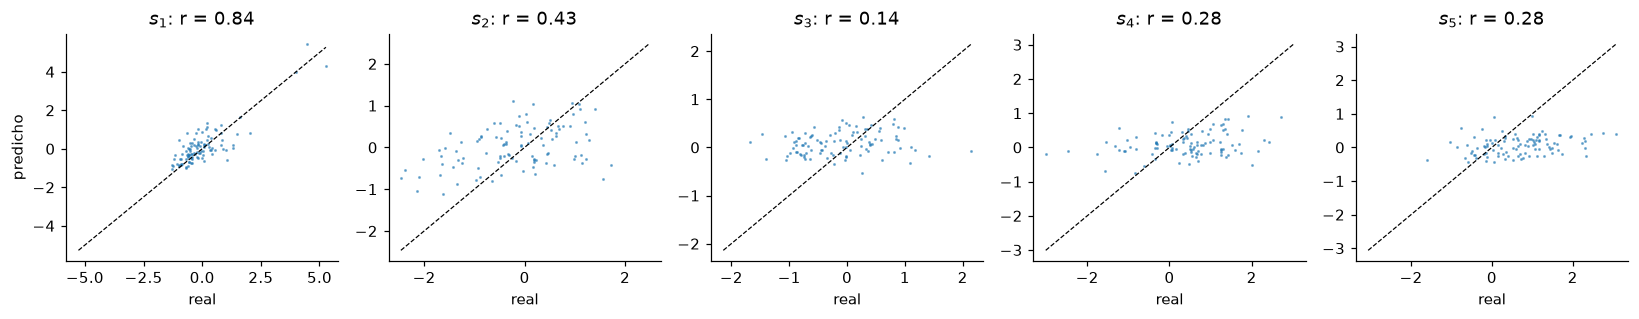

In [21]:
Ab.grafica_puntajes(D, finales['KAN'], config['KAN']['M'], mejor_oni); plt.show()

### Error por péntada y residuo medio

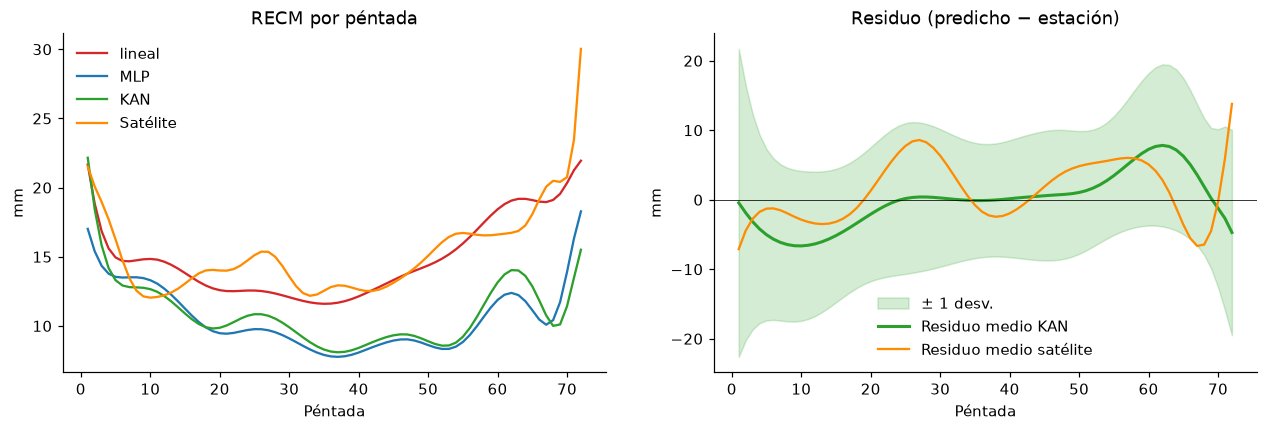

In [22]:
Ab.grafica_error_pentada(D, predicciones); plt.show()

### Residuo por curva y péntada

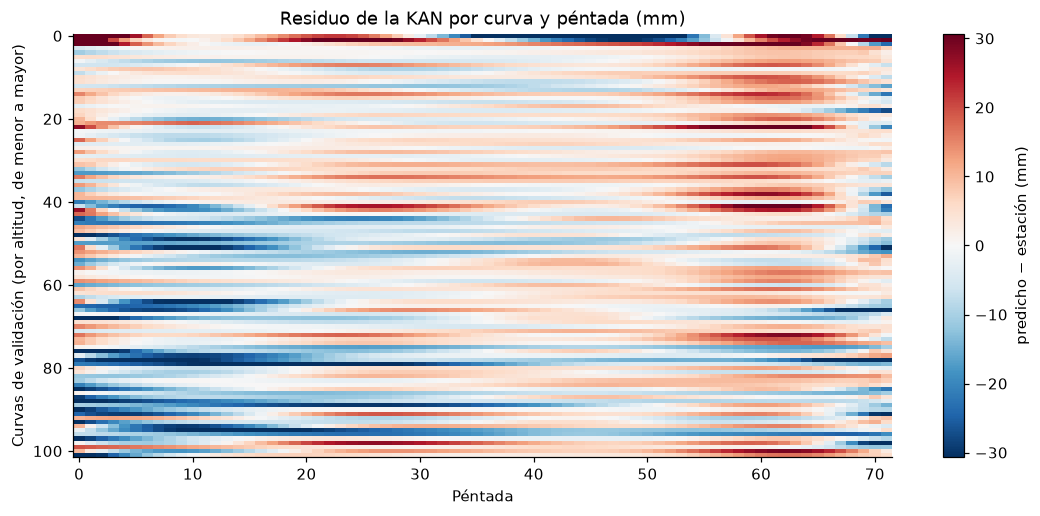

In [23]:
Ab.grafica_mapa_residuos(D, predicciones['KAN'][0], 'Residuo de la KAN por curva y péntada (mm)'); plt.show()

### Error y sesgo según altitud y fase ENSO

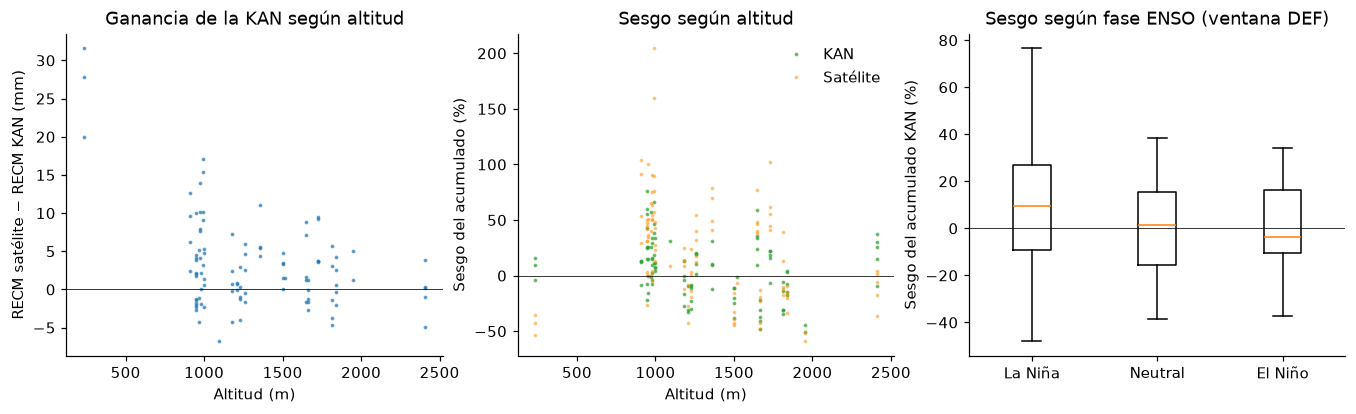

,RECM_KAN,RECM_satelite,sesgo_KAN,sesgo_satelite
fase,,,,
El Niño,6.5,11.8,-3.6,36.9
La Niña,9.0,10.9,9.5,10.5
Neutral,7.6,13.8,1.2,39.8


In [24]:
fig, tabla_enso = Ab.diagnostico_altitud_enso(D, predicciones['KAN'][0]); plt.show()
tabla_enso